In [487]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

In [488]:
filename = "G:/neural_network_from_scratch/heart diseases/heart.csv"
df = pd.read_csv(filename)
df.head(1)

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0


In [489]:
sorted_df = df[['Age','Sex','ChestPainType','RestingBP','ExerciseAngina','Oldpeak','ST_Slope','HeartDisease']]
categorical_cols = [
    'Sex',
    'ChestPainType',
    'ExerciseAngina',
    'ST_Slope'
]

df_enc = pd.get_dummies(
    sorted_df,
    columns=categorical_cols,
    dtype=int
)

In [490]:
X = df_enc.drop(['HeartDisease'],axis=1)
Y = df_enc['HeartDisease']

In [491]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

In [492]:
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (734, 14)
X_test shape: (184, 14)


In [493]:
# standardizing 
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean)/std
X_test = (X_test - mean)/std

In [494]:
Y_train = Y_train.to_numpy().reshape(-1, 1)
Y_test = Y_test.to_numpy().reshape(-1, 1)

In [495]:
X_train.head()

,Age,RestingBP,Oldpeak,Sex_F,Sex_M,ChestPainType_ASY,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,ExerciseAngina_N,ExerciseAngina_Y,ST_Slope_Down,ST_Slope_Flat,ST_Slope_Up
485,0.970012,0.339016,0.317046,-0.51740,0.51740,-1.103414,2.096917,-0.5174,-0.240077,-1.202775,1.202775,-0.26156,0.981105,-0.862246
486,0.122028,-1.266031,-0.440356,-0.51740,0.51740,-1.103414,2.096917,-0.5174,-0.240077,0.831411,-0.831411,-0.26156,-1.019259,1.159762
117,0.546020,-0.159102,0.601071,1.93274,-1.93274,0.906278,-0.476891,-0.5174,-0.240077,-1.202775,1.202775,-0.26156,0.981105,-0.862246
361,-0.725956,1.501291,-0.819056,-0.51740,0.51740,0.906278,-0.476891,-0.5174,-0.240077,-1.202775,1.202775,-0.26156,0.981105,-0.862246
296,-0.407962,0.671094,-0.156330,-0.51740,0.51740,0.906278,-0.476891,-0.5174,-0.240077,-1.202775,1.202775,-0.26156,0.981105,-0.862246


In [496]:
Y_train.shape

(734, 1)

In [497]:
class Layer_dense:
    def __init__(self,inputs,neurons):
        self.weights = np.random.randn(neurons, inputs) * 0.01
        self.biases = np.zeros((neurons,1))
    def forward(self,x):
        self.inputs = x
        self.output = np.dot(self.weights,x) + self.biases
        return self.output

class ReluActivation:
    def forward(self, inputs):
        self.inputs = inputs
        self.output = np.maximum(0, inputs)
        return self.output

    def backward(self, dvalues):
        self.dinputs = dvalues.copy()
        self.dinputs[self.inputs <= 0] = 0
        return self.dinputs

class SigmoidActivation:
    def forward(self, inputs):
        self.inputs = inputs
        inputs = np.clip(inputs, -500, 500)
        self.output = 1 / (1 + np.exp(-inputs))
        return self.output

class Loss:
    def forward(self, y_pred, y_true):
        epsilon = 1e-7
        y_pred = np.clip(y_pred, epsilon, 1-epsilon)
        loss = -(
            y_true * np.log(y_pred)
            + (1-y_true) * np.log(1-y_pred)
        )
        return np.mean(loss)

In [498]:
layer_1 = Layer_dense(14,64)
layer_2 = Layer_dense(64,1)

relu = ReluActivation()

sigmoid = SigmoidActivation()
loss_function = Loss()

In [499]:
X_train = X_train.T
Y_train = Y_train.T

print(X_train.shape)
print(Y_train.shape)

(14, 734)
(1, 734)


In [500]:
def gradient(X,y,y_pred):
    m = X.shape[1]
    error = y_pred - y
    dw = np.dot(error,X.T)/m
    db = np.sum(error)/m
    return dw,db

In [501]:
def output_layer_gradients(y_pred, y, A1):
    m = y.shape[1]
    dZ2 = y_pred - y
    dW2 = np.dot(dZ2, A1.T) / m
    db2 = np.sum(dZ2, axis=1, keepdims=True) / m
    return dZ2, dW2, db2

In [502]:
def backward(X, y, y_pred, layer_2, relu):
    m = X.shape[1]
    dZ2 = y_pred - y
    dW2 = np.dot(dZ2, relu.output.T) / m
    db2 = np.sum(dZ2, axis=1, keepdims=True) / m
    dA1 = np.dot(layer_2.weights.T, dZ2)
    dZ1 = relu.backward(dA1)
    dW1 = np.dot(dZ1, X.T) / m
    db1 = np.sum(dZ1, axis=1, keepdims=True) / m
    return dW1, db1, dW2, db2

In [503]:
def update_parameters(layer_1, layer_2,dW1, db1, dW2, db2, learning_rate):
    layer_1.weights -= learning_rate * dW1
    layer_1.biases -= learning_rate * db1
    layer_2.weights -= learning_rate * dW2
    layer_2.biases -= learning_rate * db2

In [504]:
best_loss = float('inf')

best_W1 = None
best_b1 = None
best_W2 = None
best_b2 = None

In [505]:
learning_rate = 0.1
epochs = 5000

epoch_list = [n for n in range(1,epochs+1)]
loss_history = []

for epoch in range(epochs):

    z1 = layer_1.forward(X_train)
    a1 = relu.forward(z1)

    z2 = layer_2.forward(a1)
    a2 = sigmoid.forward(z2)

    y_pred = a2
    loss = loss_function.forward(y_pred,Y_train)
    loss_history.append(loss)

    dW1, db1, dW2, db2 = backward(X_train, Y_train, y_pred, layer_2, relu)
    update_parameters(
        layer_1, layer_2,
        dW1, db1, dW2, db2,
        learning_rate
    )

    if loss < best_loss:
        best_loss = loss
        best_W1 = layer_1.weights.copy()
        best_b1 = layer_1.biases.copy()
        best_W2 = layer_2.weights.copy()
        best_b2 = layer_2.biases.copy()

    if epoch % 500 == 0:
        print(f"Epoch: {epoch}, Loss: {loss:.6f}")


Epoch: 0, Loss: 0.692539
Epoch: 500, Loss: 0.333383
Epoch: 1000, Loss: 0.318575
Epoch: 1500, Loss: 0.303604
Epoch: 2000, Loss: 0.288589
Epoch: 2500, Loss: 0.274927
Epoch: 3000, Loss: 0.264697
Epoch: 3500, Loss: 0.256092
Epoch: 4000, Loss: 0.248499
Epoch: 4500, Loss: 0.241154


In [506]:
layer_1.weights = best_W1
layer_1.biases = best_b1
layer_2.weights = best_W2
layer_2.biases = best_b2

print("Best loss:", best_loss)

Best loss: 0.23458679623299328


In [507]:
np.savez(
    "best_heart_disease_model.npz",
    W1=best_W1,
    b1=best_b1,
    W2=best_W2,
    b2=best_b2,
    mean=mean,
    std=std
)
print("model saved!")

model saved!


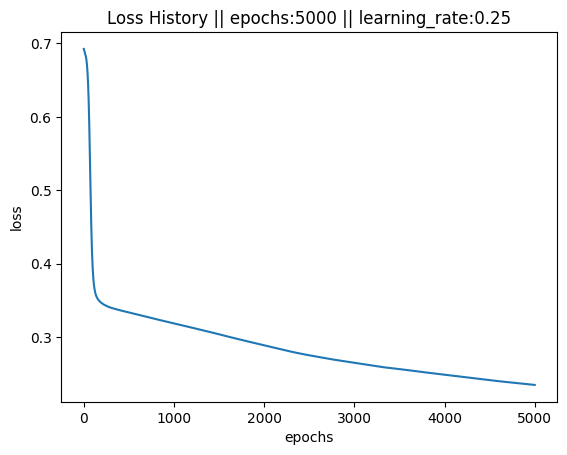

In [508]:
#plotting loss history
plt.plot(epoch_list,loss_history)
plt.xlabel("epochs")
plt.ylabel("loss")
plt.title("Loss History || epochs:5000 || learning_rate:0.25")
plt.show()

In [509]:
X_test = X_test.T
Y_test = Y_test.T

In [510]:
# examining on test data

layer_1.weights = best_W1.copy()
layer_1.biases = best_b1.copy()
layer_2.weights = best_W2.copy()
layer_2.biases = best_b2.copy()

z1_test = layer_1.forward(X_test)
a1_test = relu.forward(z1_test)

z2_test = layer_2.forward(a1_test)
y_pred_test = sigmoid.forward(z2_test)

test_loss = loss_function.forward(y_pred_test, Y_test)

print("Test Loss:", test_loss)

Test Loss: 0.4062569641263275


In [511]:
y_pred_classes = (y_pred_test >= 0.5).astype(int)

accuracy = np.mean(y_pred_classes == Y_test)

print("Test Accuracy:", accuracy * 100, "%")

Test Accuracy: 84.78260869565217 %


In [512]:
from sklearn.metrics import confusion_matrix, classification_report

print("Confusion Matrix:")
print(confusion_matrix(
    Y_test.flatten(),
    y_pred_classes.flatten()
))

print("\nClassification Report:")
print(classification_report(
    Y_test.flatten(),
    y_pred_classes.flatten()
))

Confusion Matrix:
[[71 11]
 [17 85]]

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.87      0.84        82
           1       0.89      0.83      0.86       102

    accuracy                           0.85       184
   macro avg       0.85      0.85      0.85       184
weighted avg       0.85      0.85      0.85       184



In [513]:
wrong = (y_pred_classes != Y_test)

wrong_probabilities = y_pred_test[wrong]

print("Incorrect prediction probabilities:")
print(wrong_probabilities)

print("Minimum:", np.min(wrong_probabilities))
print("Maximum:", np.max(wrong_probabilities))

Incorrect prediction probabilities:
[0.28117982 0.50293928 0.48667369 0.37727463 0.10333435 0.26652706
 0.68492728 0.85087262 0.99987845 0.28504883 0.34651921 0.83726963
 0.69010756 0.38909768 0.46816103 0.07574693 0.02331704 0.99151565
 0.39678922 0.59215237 0.01273524 0.97111741 0.86857616 0.34629786
 0.92230257 0.4487064  0.04756935 0.32550653]
Minimum: 0.012735243883243517
Maximum: 0.9998784468977485
